# GEM-Bench Evaluation Analysis

Qualitative and Quantitative evaluation of ad-injected response quality across different **Base LLM** and **Judge LLM** combinations.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

OUTPUT_BASE = '/home/gpuuser7/gpuuser7_a/prateek/GEM-Bench/GemBench/benchmarking/output/evaluate_results/output'

# Experiment configurations
EXPERIMENTS = [
    {
        'base_llm': 'gemma-3-27b-it',
        'judge': 'llama-3.3-70b',
        'dir': '20260928_082937_judge_llama-3.3-70b-instruct-fp8_base_gemma-3-27b-it',
    },
    # {
    #     'base_llm': 'gemma-3-27b-it',
    #     'judge': 'deepseek-r1-distill-qwen-32b',
    #     'dir': '20260929_175358_judge_deepseek-r1-distill-qwen-32b_base_gemma-3-27b-it',
    # }
]

QUALITATIVE_METRICS = ['accuracy', 'naturalness', 'personality', 'trust', 'notice_products', 'click_products', 'identifiability']
METRIC_DISPLAY = {
    'accuracy': 'Accuracy',
    'naturalness': 'Naturalness',
    'personality': 'Personality',
    'trust': 'Trust',
    'notice_products': 'Notice',
    'click_products': 'Click',
    'identifiability': 'Identifiability',
}

QUANTITATIVE_METRICS = ['local measure', 'global_coherence', 'global measure', 'ad_content_alignment', 'has_ad', 'product_selection_accuracy', 'in_token', 'out_token']
QUANT_METRIC_DISPLAY = {
    'local measure': 'RF',
    'global_coherence': 'RC',
    'global measure': 'AF',
    'ad_content_alignment': 'AC',
    'has_ad': 'IR',
    'product_selection_accuracy': 'CTR',
    'in_token': 'In-Token',
    'out_token': 'Out-Token',
}


In [2]:
def load_results(xlsx_path):
    """Parse the evaluation_result_average.xlsx format."""
    df = pd.read_excel(xlsx_path, header=None)
    
    # Build column names from rows 1 (top-level) and 2 (metric names)
    row1 = df.iloc[1].tolist()
    row2 = df.iloc[2].tolist()
    cols = []
    for r1, r2 in zip(row1, row2):
        if pd.notna(r1) and str(r1) != 'nan':
            cols.append(str(r1))
        elif pd.notna(r2) and str(r2) != 'nan':
            cols.append(str(r2))
        else:
            cols.append('unknown')
    
    data = df.iloc[3:].reset_index(drop=True)
    data.columns = cols
    data['data_set'] = data['data_set'].ffill()
    
    # Convert metric columns to numeric
    for m in QUALITATIVE_METRICS:
        if m in data.columns:
            data[m] = pd.to_numeric(data[m], errors='coerce')
    for m in QUANTITATIVE_METRICS:
        if m in data.columns:
            data[m] = pd.to_numeric(data[m], errors='coerce')
    
    return data

# Load all experiments
all_results = []
for exp in EXPERIMENTS:
    path = f"{OUTPUT_BASE}/{exp['dir']}/evaluation_result_average.xlsx"
    df = load_results(path)
    df['base_llm'] = exp['base_llm']
    df['judge'] = exp['judge']
    all_results.append(df)

combined = pd.concat(all_results, ignore_index=True)
print(f"Loaded {len(combined)} rows from {len(EXPERIMENTS)} experiments")
print(f"Datasets: {combined['data_set'].unique().tolist()}")
print(f"Solutions: {combined['solution'].unique().tolist()}")
print(f"Base LLMs: {combined['base_llm'].unique().tolist()}")
print(f"Judges: {combined['judge'].unique().tolist()}")


Loaded 15 rows from 1 experiments
Datasets: ['CA_Prod', 'LM-Market', 'MT-Human']
Solutions: ['Ad-Chat', 'GI-R', 'GI-P', 'GIR-R', 'GIR-P']
Base LLMs: ['gemma-3-27b-it']
Judges: ['llama-3.3-70b']


In [3]:
def build_paper_table(combined_df, dataset_filter=None, solution_filter=None):
    """Build a table in the paper format: Dataset | Base LLM | Judge LLM | Solution | Metrics."""
    
    df = combined_df.copy()
    if dataset_filter:
        df = df[df['data_set'].isin(dataset_filter)]
    if solution_filter:
        df = df[df['solution'].isin(solution_filter)]
    
    # Build the table rows
    rows = []
    for ds in df['data_set'].unique():
        ds_data = df[df['data_set'] == ds]
        for base in ds_data['base_llm'].unique():
            base_data = ds_data[ds_data['base_llm'] == base]
            for judge in base_data['judge'].unique():
                judge_data = base_data[base_data['judge'] == judge]
                for sol in judge_data['solution'].unique():
                    sol_data = judge_data[judge_data['solution'] == sol]
                    row = {
                        'Dataset': ds,
                        'Base LLM': base,
                        'Judge LLM': judge,
                        'Solution': sol,
                    }
                    vals_for_overall = []
                    for m in QUALITATIVE_METRICS:
                        val = sol_data[m].values[0]
                        if pd.notna(val) and str(val).lower() != 'nan':
                            row[METRIC_DISPLAY[m]] = round(float(val), 2)
                            vals_for_overall.append(float(val))
                        else:
                            row[METRIC_DISPLAY[m]] = '—'
                    
                    if len(vals_for_overall) > 0:
                        row['Overall'] = round(sum(vals_for_overall) / len(vals_for_overall), 2)
                    else:
                        row['Overall'] = '—'
                    rows.append(row)
    
    table = pd.DataFrame(rows)
    return table

# Build full table with Ad-Chat and GIR-R (matching paper format)
def build_quant_paper_table(combined_df, dataset_filter=None, solution_filter=None):
    """Build a quantitative table in the paper format."""
    df = combined_df.copy()
    if dataset_filter:
        df = df[df['data_set'].isin(dataset_filter)]
    if solution_filter:
        df = df[df['solution'].isin(solution_filter)]
        
    rows = []
    for ds in df['data_set'].unique():
        ds_data = df[df['data_set'] == ds]
        for base in ds_data['base_llm'].unique():
            base_data = ds_data[ds_data['base_llm'] == base]
            for judge in base_data['judge'].unique():
                judge_data = base_data[base_data['judge'] == judge]
                for sol in judge_data['solution'].unique():
                    sol_data = judge_data[judge_data['solution'] == sol]
                    row = {
                        'Dataset': ds,
                        'Base LLM': base,
                        'Judge LLM': judge,
                        'Solution': sol,
                    }
                    for m in QUANTITATIVE_METRICS:
                        val = sol_data[m].values[0] if m in sol_data.columns else float('nan')
                        if pd.notna(val) and str(val).lower() != 'nan':
                            row[QUANT_METRIC_DISPLAY.get(m, m)] = round(float(val), 2)
                        else:
                            row[QUANT_METRIC_DISPLAY.get(m, m)] = '—'
                    rows.append(row)
    table = pd.DataFrame(rows)
    return table


In [4]:
def style_table(df, title=''):
    """Style a DataFrame to bold the best value per (Dataset, Solution) group for each metric."""
    metric_cols = list(METRIC_DISPLAY.values()) + ['Overall']
    
    def bold_max_by_dataset(data):
        styles = pd.DataFrame('', index=data.index, columns=data.columns)
        for ds in data['Dataset'].unique():
            ds_idx = data[data['Dataset'] == ds].index
            for col in metric_cols:
                if col in data.columns:
                    numeric_s = pd.to_numeric(data.loc[ds_idx, col], errors='coerce')
                    if numeric_s.notna().any():
                        max_val = numeric_s.max()
                        is_max = numeric_s == max_val
                        styles.loc[ds_idx[is_max], col] = 'font-weight: bold'
        return styles
    
    styled = (df.style
              .apply(bold_max_by_dataset, axis=None)
              .set_caption(title)
              .format(precision=2)
              .set_table_styles([
                  {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('padding', '10px')]},
                  {'selector': 'th', 'props': [('background-color', '#f0f0f0'), ('padding', '8px')]},
                  {'selector': 'td', 'props': [('padding', '6px 12px')]},
              ])
              .hide(axis='index'))
    return styled


In [5]:
def style_quant_table(df, title=''):
    metric_cols = list(QUANT_METRIC_DISPLAY.values()) + ['Overall']
    
    def bold_max_by_dataset(data):
        styles = pd.DataFrame('', index=data.index, columns=data.columns)
        for ds in data['Dataset'].unique():
            ds_idx = data[data['Dataset'] == ds].index
            for col in metric_cols:
                if col in data.columns:
                    numeric_s = pd.to_numeric(data.loc[ds_idx, col], errors='coerce')
                    if numeric_s.notna().any():
                        max_val = numeric_s.max()
                        is_max = numeric_s == max_val
                        styles.loc[ds_idx[is_max], col] = 'font-weight: bold'
        return styles
    
    styled = (df.style
              .apply(bold_max_by_dataset, axis=None)
              .set_caption(title)
              .format(precision=2)
              .set_table_styles([
                  {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('padding', '10px')]},
                  {'selector': 'th', 'props': [('background-color', '#f0f0f0'), ('padding', '8px')]},
                  {'selector': 'td', 'props': [('padding', '6px 12px')]},
              ])
              .hide(axis='index'))
    return styled


In [ ]:
# GI-R vs GI-P Comparison

DATASET_ORDER = ['MT-Human', 'LM-Market', 'CA_Prod']

for judge in combined['judge'].unique():
    judge_df = combined[combined['judge'] == judge]
    print(f"Judge: {judge}")
    print("=" * 50)
    
    for ds in DATASET_ORDER:
        sub = judge_df[(judge_df['data_set'] == ds) & (judge_df['solution'].isin(['GI-R', 'GI-P']))]
        if sub.empty:
            continue
        
        # Qualitative
        qual_cols = ['accuracy', 'naturalness', 'personality', 'trust', 'notice_products', 'click_products', 'identifiability']
        qual_display = {'accuracy': 'Acc', 'naturalness': 'Nat', 'personality': 'Per', 'trust': 'Tru',
                        'notice_products': 'Not', 'click_products': 'Cli', 'identifiability': 'Idt'}
        qual = sub[['solution'] + qual_cols].set_index('solution').rename(columns=qual_display).reindex(['GI-R', 'GI-P']).round(2)
        print(f"\n  {ds} - Qualitative")
        display(qual)
        gi_r_avg = qual.loc['GI-R'].mean()
        gi_p_avg = qual.loc['GI-P'].mean()
        winner = 'GI-R' if gi_r_avg >= gi_p_avg else 'GI-P'
        print(f"  → Winner: {winner} (GI-R avg={gi_r_avg:.2f}, GI-P avg={gi_p_avg:.2f})")
        
        # Quantitative
        quant_cols = [c for c in ['local measure', 'global_coherence', 'global measure', 'ad_content_alignment', 'has_ad', 'product_selection_accuracy'] if c in sub.columns]
        quant_display = {'local measure': 'RF', 'global_coherence': 'RC', 'global measure': 'AF',
                         'ad_content_alignment': 'AC', 'has_ad': 'IR', 'product_selection_accuracy': 'CTR'}
        quant = sub[['solution'] + quant_cols].set_index('solution').rename(columns=quant_display).reindex(['GI-R', 'GI-P']).round(2)
        print(f"  {ds} - Quantitative")
        display(quant)
        gi_r_avg_q = quant.loc['GI-R'].mean()
        gi_p_avg_q = quant.loc['GI-P'].mean()
        winner_q = 'GI-R' if gi_r_avg_q >= gi_p_avg_q else 'GI-P'
        print(f"  → Winner: {winner_q} (GI-R avg={gi_r_avg_q:.2f}, GI-P avg={gi_p_avg_q:.2f})")
    print()


Judge: llama-3.3-70b

  MT-Human - Qualitative


,Acc,Nat,Per,Tru,Not,Cli,Idt
solution,,,,,,,
GI-R,90.0,76.0,88.0,86.0,60.0,75.0,58.63
GI-P,90.0,70.0,86.0,85.0,58.0,71.0,61.90


  → Winner: GI-R (GI-R avg=76.23, GI-P avg=74.56)
  MT-Human - Quantitative


,RF,RC,AF,AC,IR,CTR
solution,,,,,,
GI-R,37.24,59.20,80.13,42.12,100.0,NaN
GI-P,36.97,59.04,79.59,38.26,100.0,NaN


  → Winner: GI-R (GI-R avg=63.74, GI-P avg=62.77)

  LM-Market - Qualitative


...

  → Winner: GI-R (GI-R avg=64.32, GI-P avg=63.86)

  CA_Prod - Qualitative


,Acc,Nat,Per,Tru,Not,Cli,Idt
solution,,,,,,,
GI-R,70.20,18.89,42.95,28.61,30.00,81.39,35.52
GI-P,72.11,19.79,44.05,29.09,30.58,81.65,35.82


  → Winner: GI-P (GI-R avg=43.94, GI-P avg=44.73)
  CA_Prod - Quantitative


,RF,RC,AF,AC,IR,CTR
solution,,,,,,
GI-R,37.60,67.24,83.62,60.38,100.0,29.78
GI-P,37.61,68.16,84.33,59.83,100.0,35.26


  → Winner: GI-P (GI-R avg=63.10, GI-P avg=64.20)



In [ ]:
# Quantitative Comparison: GI-R vs GI-P
DATASET_ORDER = ['MT-Human', 'LM-Market', 'CA_Prod']
for judge in combined['judge'].unique():
    judge_df = combined[combined['judge'] == judge]
    print(f"Judge: {judge}")
    print("=" * 50)
    for ds in DATASET_ORDER:
        sub = judge_df[(judge_df['data_set'] == ds) & (judge_df['solution'].isin(['GI-R', 'GI-P']))]
        if sub.empty:
            continue
        
        quant_cols = [c for c in ['local measure', 'global_coherence', 'global measure', 'ad_content_alignment', 'has_ad', 'product_selection_accuracy'] if c in sub.columns]
        quant_display = {'local measure': 'RF', 'global_coherence': 'RC', 'global measure': 'AF', 'ad_content_alignment': 'AC', 'has_ad': 'IR', 'product_selection_accuracy': 'CTR'}
        quant = sub[['solution'] + quant_cols].set_index('solution').rename(columns=quant_display).reindex(['GI-R', 'GI-P']).round(2)
        
        print(f"\n  {ds} - Quantitative (GI-R vs GI-P)")
        display(quant)
        
        if not quant.empty:
            gi_r_avg_q = quant.loc['GI-R'].mean()
            gi_p_avg_q = quant.loc['GI-P'].mean()
            winner_q = 'GI-R' if gi_r_avg_q >= gi_p_avg_q else 'GI-P'
            print(f"  → Quantitative Winner: {winner_q} (GI-R avg={gi_r_avg_q:.2f}, GI-P avg={gi_p_avg_q:.2f})")
        print()


## Token Usage Comparison by Variant
Comparison of the average input and output tokens consumed across all methods.

,Avg In-Tokens,Avg Out-Tokens,Total Tokens
solution,,,
GI-P,16.8,547.3,564.1
GI-R,16.8,547.3,564.1
GIR-P,669.0,1139.6,1808.6
GIR-R,673.8,1140.9,1814.7
Ad-Chat,1553.3,801.8,2355.1


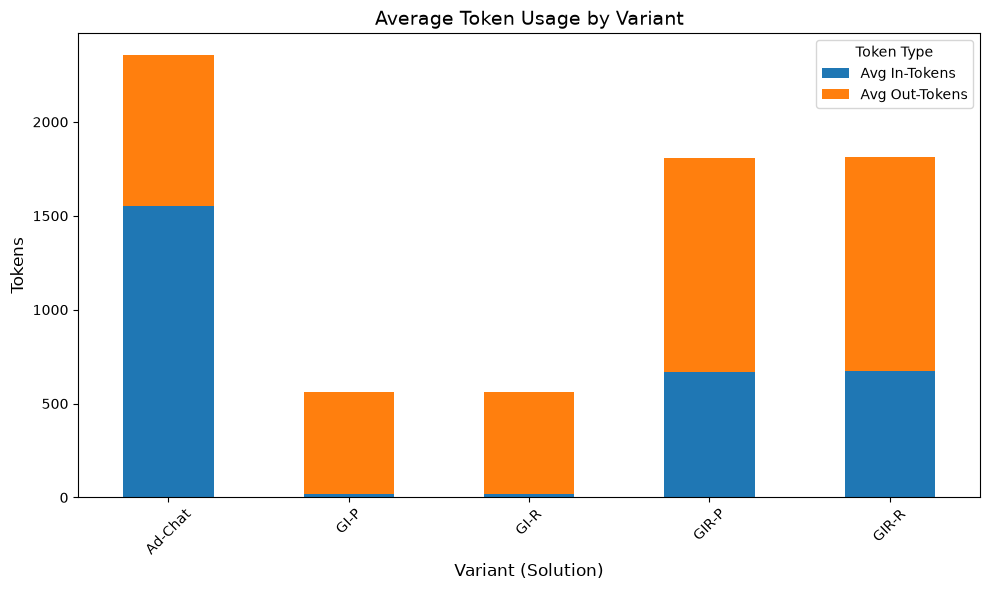

In [7]:
# Group by solution (variant) and calculate mean for in_token and out_token
token_usage = combined.groupby('solution')[['in_token', 'out_token']].mean().round(1)
token_usage.columns = ['Avg In-Tokens', 'Avg Out-Tokens']
token_usage['Total Tokens'] = token_usage['Avg In-Tokens'] + token_usage['Avg Out-Tokens']
display(token_usage.sort_values('Total Tokens'))

# Bar chart visualization
import matplotlib.pyplot as plt
ax = token_usage[['Avg In-Tokens', 'Avg Out-Tokens']].plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Average Token Usage by Variant', fontsize=14)
plt.ylabel('Tokens', fontsize=12)
plt.xlabel('Variant (Solution)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Token Type')
plt.tight_layout()
plt.show()